<a href="https://colab.research.google.com/github/Vukhanhvan09/Khai-ph-d-li-u/blob/main/Khai_pha_du_lieu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving tiki_dataset.zip to tiki_dataset.zip


In [ ]:
import zipfile
with zipfile.ZipFile('tiki_dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('tiki_dataset')


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV

#**PHẦN A — TIỀN XỬ LÝ & PHÂN TÍCH VĂN BẢN**

## **A.1 Khám phá dữ liệu ban đầu**

### **Câu A1:**

In [ ]:
data = []
folder_path = "tiki_dataset/tiki_dataset"
for file in os.listdir(folder_path):
    if file.endswith(".txt"):
        file_path = os.path.join(folder_path, file)
        with open(file_path, "r", encoding="utf-8") as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split("\t")
                if len(parts) == 8:
                    data.append(parts)
print("Số dòng dữ liệu:", len(data))

Số dòng dữ liệu: 13652


In [ ]:
columns = [
    "product_id",
    "customer_name",
    "rating",
    "review_title",
    "helpful_votes",
    "verified_purchase",
    "review_date",
    "review_text"
]
df = pd.DataFrame(data, columns=columns)
df.to_csv("tiki_reviews.csv", index=False, encoding= "utf-8-sig")

In [ ]:
df = pd.read_csv("tiki_reviews.csv")
df.head(10)

,product_id,customer_name,rating,review_title,helpful_votes,verified_purchase,review_date,review_text
0,SonMauDuongMoiMaybellineRebelBouquet39G,Thùy Duyên,100,Rất tốt,0,False,2 ngày trước,Rất hài lòng về sản phẩm . Màu son lên...
1,SonMauDuongMoiMaybellineRebelBouquet39G,Nhung Miêu,100,Tốt,0,False,2 ngày trước,"Mình lúc đầu chỉ dùng ké thôi , hihi . Nhưng ..."
2,SonMauDuongMoiMaybellineRebelBouquet39G,Lâm Nguyễn Đoan Trang,80,Tốt,0,False,2 ngày trước,Maybelline là hãng drugstore yêu_thích của rấ...
3,SonMauDuongMoiMaybellineRebelBouquet39G,Hồ Trần Bảo Ngọc,100,Màu son đẹp!,0,True,2 ngày trước,Mình vừa nhận được hàng ngày hôm_qua . Tiki g...
4,SonMauDuongMoiMaybellineRebelBouquet39G,Nguyễn Dung,100,Ưng lắm <3,0,True,3 ngày trước,Tối nay có hẹn thì nhận được thông_báo Tiki g...
5,SonMauDuongMoiMaybellineRebelBouquet39G,Thanh Nga,80,Cũng tạm,0,True,5 ngày trước,Mình mua son màu cam sữa . Màu son lên không ...
6,SonMauDuongMoiMaybellineRebelBouquet39G,Lưu Trúc Xinh,80,Nhận xét,0,True,6 ngày trước,Mình mới mua sp này . Chưa dùng nhiều nhưng t...
7,SonMauDuongMoiMaybellineRebelBouquet39G,Trương Tố,60,Khá tốt.,0,False,1 tuần trước,Tôi được tặng và nó là mẫu_số 3 . Son thiết_k...
8,SonMauDuongMoiMaybellineRebelBouquet39G,Nhạn Huỳnh,100,rất ưng ý,0,True,1 tuần trước,"Mình mới mua một son màu hồng tím ( 10) , lên..."
9,SonMauDuongMoiMaybellineRebelBouquet39G,Nhung Nguyễn,100,sản phẩm rất tốt,0,True,2 tuần trước,Trời_ơi vừa nhận đc hàng . Giao nhanh kinh_kh...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13652 entries, 0 to 13651
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   product_id         13652 non-null  object
 1   customer_name      13652 non-null  object
 2   rating             13652 non-null  int64 
 3   review_title       13652 non-null  object
 4   helpful_votes      13652 non-null  int64 
 5   verified_purchase  13652 non-null  bool  
 6   review_date        13652 non-null  object
 7   review_text        13652 non-null  object
dtypes: bool(1), int64(2), object(5)
memory usage: 760.1+ KB


In [ ]:
df.shape

(13652, 8)

In [ ]:
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

def gan_nhan(rating):
  if rating >= 80:
    return "positive"
  elif rating >= 50 and rating < 80:
    return "neutral"
  else:
    return "negative"
df["sentiment"] = df["rating"].apply(gan_nhan)
df.head(10)

,product_id,customer_name,rating,review_title,helpful_votes,verified_purchase,review_date,review_text,sentiment
0,SonMauDuongMoiMaybellineRebelBouquet39G,Thùy Duyên,100,Rất tốt,0,False,2 ngày trước,Rất hài lòng về sản phẩm . Màu son lên...,positive
1,SonMauDuongMoiMaybellineRebelBouquet39G,Nhung Miêu,100,Tốt,0,False,2 ngày trước,"Mình lúc đầu chỉ dùng ké thôi , hihi . Nhưng ...",positive
2,SonMauDuongMoiMaybellineRebelBouquet39G,Lâm Nguyễn Đoan Trang,80,Tốt,0,False,2 ngày trước,Maybelline là hãng drugstore yêu_thích của rấ...,positive
3,SonMauDuongMoiMaybellineRebelBouquet39G,Hồ Trần Bảo Ngọc,100,Màu son đẹp!,0,True,2 ngày trước,Mình vừa nhận được hàng ngày hôm_qua . Tiki g...,positive
4,SonMauDuongMoiMaybellineRebelBouquet39G,Nguyễn Dung,100,Ưng lắm <3,0,True,3 ngày trước,Tối nay có hẹn thì nhận được thông_báo Tiki g...,positive
5,SonMauDuongMoiMaybellineRebelBouquet39G,Thanh Nga,80,Cũng tạm,0,True,5 ngày trước,Mình mua son màu cam sữa . Màu son lên không ...,positive
6,SonMauDuongMoiMaybellineRebelBouquet39G,Lưu Trúc Xinh,80,Nhận xét,0,True,6 ngày trước,Mình mới mua sp này . Chưa dùng nhiều nhưng t...,positive
7,SonMauDuongMoiMaybellineRebelBouquet39G,Trương Tố,60,Khá tốt.,0,False,1 tuần trước,Tôi được tặng và nó là mẫu_số 3 . Son thiết_k...,neutral
8,SonMauDuongMoiMaybellineRebelBouquet39G,Nhạn Huỳnh,100,rất ưng ý,0,True,1 tuần trước,"Mình mới mua một son màu hồng tím ( 10) , lên...",positive
9,SonMauDuongMoiMaybellineRebelBouquet39G,Nhung Nguyễn,100,sản phẩm rất tốt,0,True,2 tuần trước,Trời_ơi vừa nhận đc hàng . Giao nhanh kinh_kh...,positive


In [ ]:
df["sentiment"].value_counts()

,count
sentiment,
positive,11684
neutral,1614
negative,354


Câu A1:
- Bộ dữ liệu ban đầu bao gồm các file .txt thô, không được phân theo hàng, cột. Các dữ liệu cách nhau bởi dấu cách đơn thuần, gây khó khăn cho việc phân tích và trực quan hoá dữ liệu.
- Dựa vào các bước xử lý ban đầu, nhóm tiến hành gộp toàn bộ dữ liệu trong các file .txt thành 1 dataFrame lớn, đặt tên cho các cột dữ liệu và chuyển đổi sang file .csv
- Bộ dữ liệu sau khi chuyển đổi bao gồm 13652 mẫu và 8 cột dữ liệu lần lượt là:
  + product_id: mã/tên sản phẩm
  + customer_name: tên khách hàng
  + rating: điểm đánh giá sản phẩm
  + review_title: tiêu đề đánh giá sản phẩm
  + helpful_votes: bình chọn đánh giá hữu ích
  + verified_purchase: xác thực mua hàng
  + review_date: thời gian đánh giá
  + review_text: nội dung đánh giá
- Ban đầu, đa phần các cột trong bộ dữ liệu đều mang kiểu dữ liệu "object" ngoại trừ cột helpful_votes có kiểu dữ liệu là "int" và cột verified_purchase có kiểu dữ liệu "boolean"
- Để phục vụ bài toán phân tích cảm xúc, nhóm đã chia bộ dữ liệu theo 3 nhãn dựa vào số điểm mà khách hàng đánh giá cho sản phẩm. Cụ thể:
  + Nếu rating >= 80, mẫu dữ liệu sẽ được gán nhãn "positive"(tổng cộng có 11684 mẫu)
  + Nếu rating nằm trong khoảng từ 50 đến nhỏ hơn 80, mẫu dữ liệu sẽ được gán nhãn "neutral" (tổng cộng có 1614 mẫu)
  + Cuối cùng, nếu rating < 50, mẫu dữ liệu sẽ được gán nhãn "negative" (tổng cộng 354 mẫu)
- Nhận xét:ta có thể dễ dàng nhận thấy dữ liệu đang bị mất cân bằng nghiêm trọng khi số lượng mẫu "positive" áp đảo số lượng mẫu "neutral" và "negative". Điều này gây ảnh hưởng lớn đến quá trình huấn luyện mô hình:
  + Mô hình dễ thiên về dự đoán lớp positive.
  + Độ chính xác của mô hình có thể cao nhưng khả năng nhận diện negative và neutral rất kém.
  + Recall và F1-score của lớp negative và lớp neutral có thể thấp.





### **Câu A2**

In [ ]:
df["ky_tu"] = df["review_text"].str.len()
df["so_tu"] = df["review_text"].str.split().str.len()
df.groupby("sentiment")[["ky_tu"]].describe()


ky_tu                                                       \
             count        mean         std    min     25%    50%    75%   
sentiment                                                                 
negative     354.0  352.429379  134.554840  201.0  253.25  305.5  409.0   
neutral     1614.0  324.330855  102.576176  165.0  251.00  292.0  367.5   
positive   11684.0  328.408507  107.063820  120.0  257.00  297.0  367.0   

                   
              max  
sentiment          
negative   1110.0  
neutral    1004.0  
positive   2082.0

In [ ]:
df.groupby("sentiment")[["so_tu"]].describe()

so_tu                                                     
             count       mean        std   min   25%   50%   75%    max
sentiment                                                              
negative     354.0  76.706215  29.158522  40.0  55.0  67.5  88.0  217.0
neutral     1614.0  69.824659  22.476955  38.0  54.0  63.0  80.0  226.0
positive   11684.0  69.537658  23.029179  28.0  54.0  63.0  78.0  424.0

In [ ]:
df.groupby("sentiment")[["ky_tu", "so_tu"]].mean()

,ky_tu,so_tu
sentiment,,
negative,352.429379,76.706215
neutral,324.330855,69.824659
positive,328.408507,69.537658


Câu A2:
- Nhóm tiến hành tính toán độ dài văn bản dựa trên hai tiêu chí là số ký tự và số từ trong mỗi đánh giá. Kết quả cho thấy các đánh giá thuộc nhãn Negative có độ dài trung bình lớn nhất với khoảng 352 ký tự và 76 từ. Trong khi đó, các đánh giá Positive và Neutral có độ dài khá tương đồng, dao động trong khoảng 324-328 ký tự và 69-70 từ. Điều này cho thấy khách hàng không hài lòng về sản phẩm thường có xu hướng viết đánh giá chi tiết hơn nhằm mô tả các vấn đề bản thân họ đã gặp phải trong quá trình sử dụng sản phẩm. Ngược lại, các đánh giá tích cực và trung lập thường ngắn gọn và tập trung nhiều vào cảm nhận chung về sản phẩm hơn.
- Dựa vào số liệu vừa được tính toán, ta có thể thấy tuy có sự chênh lệch về độ dài văn bản giữa các nhãn nhưng phần chênh lệch này lại không quá lớn. Văn bản có nhãn Negative chỉ nhiều hơn khoảng 7 từ so với văn bản ở nhãn Neutral và Positive. Bên cạnh đó, độ lệch chuẩn của các nhãn đều ở mức khá cao với Negative khoảng 29 từ, Neutral khoảng 22 từ và Positive khoảng 23 từ. Điều này cho thấy ở mỗi nhãn đều tồn tại nhiều bài đánh giá có độ dài hay ngắn khác nhau. Do đó,có thể nhận xét rằng độ dài của văn bản không cho thấy mối tương quan rõ ràng với các nhãn phân loại.
- Nói tóm lại, độ dài văn bản có thể cung cấp một số thông tin hỗ trợ cho việc phân loại nhãn cảm xúc nhưng không phải yếu tố quyết định. Mặc dù các đánh giá tiêu cực có xu hướng dài hơn các đánh giá tích cực hay trung lập nhưng sự khác biệt này không đủ lớn để sử dụng cho việc phân loại. Cần phải khai thác thêm nội dung và từ vựng của văn bản đó.

## **A.2 Tiền xử lý văn bản**

### **Câu A3**

In [ ]:
  from google.colab import files
uploaded = files.upload()


Saving vietnamese-stopwords-dash.txt to vietnamese-stopwords-dash.txt


In [ ]:
sw_path = 'vietnamese-stopwords-dash.txt'
with open(sw_path, 'r', encoding='utf-8') as f:
    stopwords = set(line.strip() for line in f if line.strip())
print('Số lượng stopwords gốc ban đầu:', len(stopwords))


Số lượng stopwords gốc ban đầu: 1942


Do Python không hỗ trợ các stopword của tiếng Việt, nhóm đã sử dụng một file stopwords tiếng việt bên ngoài (vietnamese-stopwords-dash.txt) được tải lên Google Colab. Chương trình sẽ mở file ở chế độ đọc, mã hoá toàn bộ nội dung của file thành một chuỗi sau đó tách chuỗi này thành một danh sách mà trong đó mỗi dòng của tập tin tương ứng với một phần tử. Danh sách này sẽ được sử dụng ở các bước tiền xử lý tiếp theo nhằm loại bỏ các từ xuất hiện với tần suất lớn trong bộ dữ liệu cần phân tích nhưng không có nhiều tác dụng trong việc phân loại và xây dựng các mô hình sau này.
- Link github của file stopwords: https://github.com/stopwords/vietnamese-stopwords.git


In [ ]:
neg_and_sentiment_roots = [
    'không', 'chẳng', 'chưa', 'chả', 'nhưng', 'tuy_nhiên',
    'mặc_dù', 'tốt'
]
whitelist_stopwords = {w for w in stopwords if any(root in w for root in neg_and_sentiment_roots)}
stopwords = stopwords - whitelist_stopwords

print('Số lượng từ cảm xúc/phủ định được bảo vệ (whitelist):', len(whitelist_stopwords))
print('Số lượng stopwords sau khi loại trừ whitelist:', len(stopwords))


Số lượng từ cảm xúc/phủ định được bảo vệ (whitelist): 81
Số lượng stopwords sau khi loại trừ whitelist: 1861


Mặc dù sử dụng bộ stopwords tiếng Việt có sẵn, nhóm nhận thấy các từ phủ định (như "không", "chẳng", "chưa"), liên từ chỉ sự tương phản ("nhưng", "tuy_nhiên") hay các từ mang tính phân loại cảm xúc cao ("tốt", "tệ", "kém", "quá", "rất") có vai trò sống còn trong phân tích cảm xúc (Sentiment Analysis). Nếu xóa bỏ các từ này, một câu chê như "không dùng được" hay "đẹp nhưng nhanh hỏng" sẽ bị hiểu nhầm thành tích cực. Do đó, nhóm xây dựng cơ chế lọc Whitelist toàn diện để giữ lại tất cả các từ khóa mang sắc thái cảm xúc này trong quá trình tiền xử lý.

In [ ]:
domain_stopwords = {
    'sản_phẩm', 'shop', 'cửa_hàng', 'mua', 'dùng', 'hàng', 'giao_hàng',
    'giá', 'giá_cả', 'màu', 'bé', 'thử', 'tiki', 'sử_dụng',
    'đặt', 'order', 'mình', 'bạn', 'ad', 'anh', 'chị', 'em', 'thấy'
}
stopwords.update(domain_stopwords)
print('Tổng số stopwords sau khi bổ sung domain stopwords:', len(stopwords))


Tổng số stopwords sau khi bổ sung domain stopwords: 1875


Sau quá trình làm sạch và trực quan hoá, nhóm quan sát thấy trong biểu đồ WordCloud ban đầu có xuất hiện một số từ với tần suất rất cao như "sản_phẩm", "shop", "mua",...Các từ ngữ này đa phần phổ biến trong lĩnh vực thương mại điện tử và xuất hiện ở tất cả các nhãn cảm xúc. Do đó nhóm xây dựng thêm một tập domain stopwords kết hợp với file stopwords trước đó nhằm loại bỏ các từ ít giá trị phân biệt, tập trung hơn vào các từ biểu đạt cảm xúc như "hài_lòng", "tệ",.....

In [ ]:
EMOJI_DICT = {
    '😡': ' emo_neg ', '👎': ' emo_neg ', '💔': ' emo_neg ', '💩': ' emo_neg ',
    ':(': ' emo_neg ', ':-(': ' emo_neg ', '1 sao': ' emo_neg ', '2 sao': ' emo_neg ',
    '❤️': ' emo_pos ', '👍': ' emo_pos ', '😍': ' emo_pos ', ':)': ' emo_pos ',
    ':-)': ' emo_pos', '5 sao': ' emo_pos ', '4 sao': ' emo_pos '
}

def preprocess_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    for emo, rep in EMOJI_DICT.items():
        text = text.replace(emo, rep)
    text = re.sub(r'http\S+|www\S+|<[^>]+>', ' ', text)
    text = re.sub(r'[^a-zA-ZÀ-ỹ0-9_\s]', ' ', text)

    tokens = [w for w in text.split() if w not in stopwords and len(w) > 1]
    return ' '.join(tokens)


Hàm preprocess_text được nâng cấp toàn diện với mục đích chuẩn hoá và giữ lại tối đa đặc trưng cảm xúc:
- **Chuẩn hóa chữ thường & Emoji:** Ánh xạ các icon cảm xúc (như 😡, 👎, 💔, :() thành các token định danh `emo_neg`, `emo_pos` trước khi làm sạch, giúp mô hình không bị mất các dấu hiệu thể hiện cảm xúc trực quan của người dùng.
- **Loại bỏ URL & HTML:** Dọn dẹp các ký tự nhiễu không mang giá trị ngữ nghĩa.
- **Lọc Stopwords thông minh:** Áp dụng bộ stopwords đã qua tinh lọc (đã bảo vệ toàn bộ từ phủ định và từ cảm xúc), loại bỏ các từ rác của thương mại điện tử để tập trung vào các tín hiệu phân biệt cảm xúc.

In [ ]:
df["lam_sach_dl"] = df["review_text"].apply(preprocess_text)
df[["review_text", "lam_sach_dl"]].head(10)

,review_text,lam_sach_dl
0,Rất hài lòng về sản phẩm . Màu son lên...,rất hài lòng về sản phẩm màu son chuẩn...
1,"Mình lúc đầu chỉ dùng ké thôi , hihi . Nhưng ...",đầu ké hihi nhưng thỏi công_nhận ok 18t son dư...
2,Maybelline là hãng drugstore yêu_thích của rấ...,maybelline hãng drugstore yêu_thích dòng son m...
3,Mình vừa nhận được hàng ngày hôm_qua . Tiki g...,hôm_qua giao lịch hẹn cam tươi son môi mịn cam...
4,Tối nay có hẹn thì nhận được thông_báo Tiki g...,tối hẹn thông_báo giao mẫu đỏ cam lắm son đầu ...
5,Mình mua son màu cam sữa . Màu son lên không ...,son cam sữa son không hình trôi ăn_uống bù son...
6,Mình mới mua sp này . Chưa dùng nhiều nhưng t...,sp chưa nhưng ưng_ý mẫu đẹp nhưng son hơi khô ...
7,Tôi được tặng và nó là mẫu_số 3 . Son thiết_k...,tặng mẫu_số son thiết_kế đẹp_mắt son đẹp nhuen...
8,"Mình mới mua một son màu hồng tím ( 10) , lên...",son hồng tím 10 đẹp phai hồng sữa xài tốt độ b...
9,Trời_ơi vừa nhận đc hàng . Giao nhanh kinh_kh...,trời_ơi đc giao kinh_khủng gói cẩn_thận chất_l...


Áp dụng hàm preprocess_text cho cột dữ liệu review_text của dataframe ta thu về cột dữ liệu lam_sach_dl chứa văn bản đã được làm sạch. Từ đó, nhóm có thể chuẩn bị tốt dữ liệu cho phần huấn luyện mô hình học máy.


# **PHẦN B — TRỰC QUAN HÓA DỮ LIỆU**

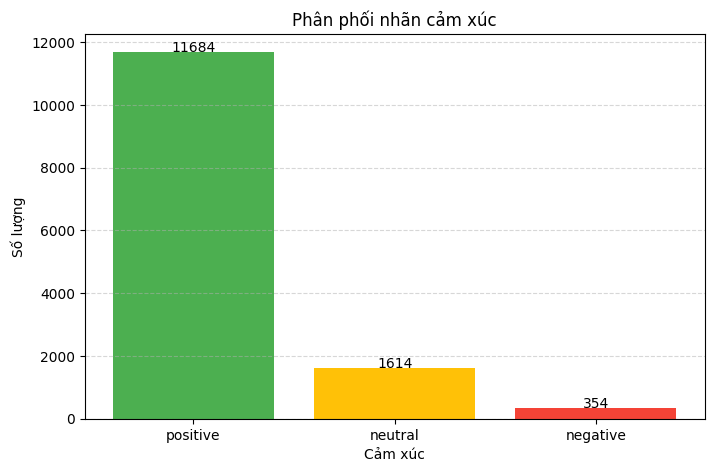

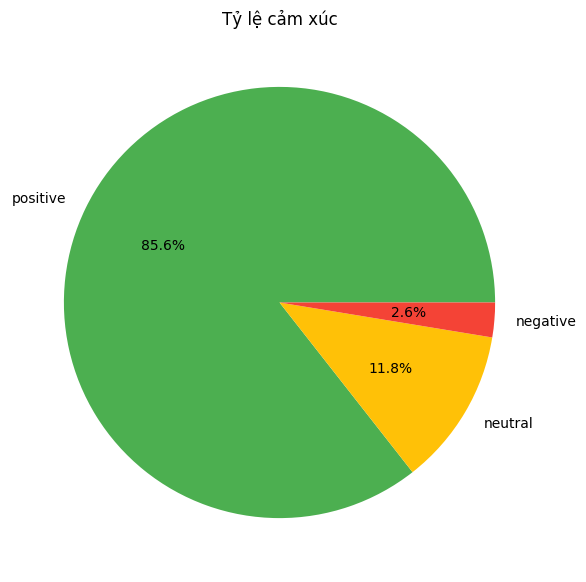

In [ ]:
df["sentiment"] = df["rating"].apply(gan_nhan)
label_counts = df["sentiment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    label_counts.index,
    label_counts.values,
    color=["#4CAF50", "#FFC107", "#F44336"]
)
plt.title("Phân phối nhãn cảm xúc")
plt.xlabel("Cảm xúc")
plt.ylabel("Số lượng")
for i, v in enumerate(label_counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

plt.figure(figsize=(7, 7))
plt.pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.1f%%",
    colors=["#4CAF50", "#FFC107", "#F44336"]
)
plt.title("Tỷ lệ cảm xúc")
plt.show()

- Biểu đồ cho thấy tập dữ liệu có sự mất cân bằng rõ rệt giữa các lớp cảm xúc. Trong tổng số 13.652 đánh giá, lớp Positive chiếm 11.684 mẫu (85,6%), lớp Neutral có 1.614 mẫu (11,8%) và lớp Negative chỉ có 354 mẫu (2,6%).

- Số lượng mẫu Positive lớn hơn khoảng 7 lần so với Neutral và hơn 30 lần so với Negative. Điều này cho thấy phần lớn khách hàng trong tập dữ liệu có xu hướng để lại các đánh giá tích cực.

- Sự mất cân bằng dữ liệu có thể khiến mô hình học máy thiên lệch về lớp Positive. Khi đó, mô hình vẫn có thể đạt độ chính xác (Accuracy) cao nhưng khả năng nhận diện các đánh giá Neutral và Negative lại không tốt.

- Đặc biệt, lớp Negative có số lượng mẫu rất ít nên mô hình dễ gặp khó khăn trong việc học các đặc trưng của nhóm này, dẫn đến Recall và F1-score thấp hơn so với các lớp còn lại.

- Tỷ lệ Positive áp đảo cũng phản ánh đặc điểm phổ biến của dữ liệu đánh giá thương mại điện tử, nơi người dùng thường để lại phản hồi khi hài lòng với sản phẩm hoặc dịch vụ.

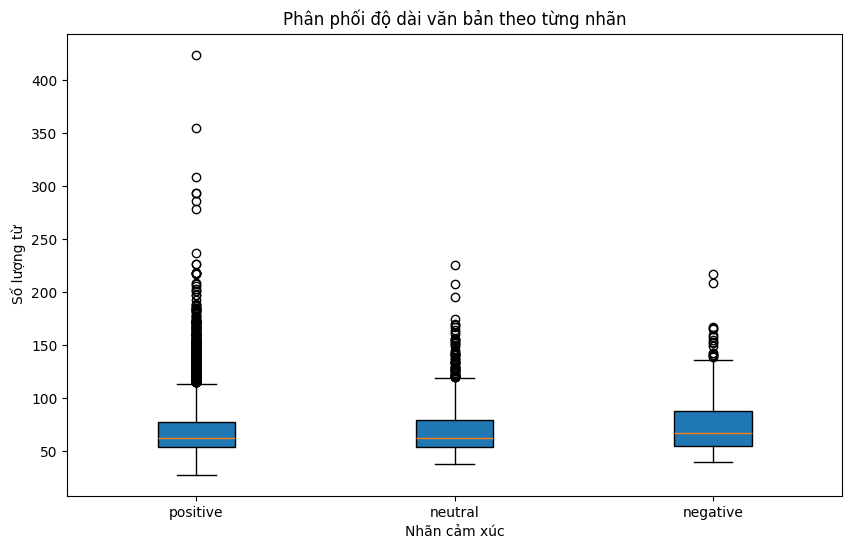

In [ ]:
labels = df["sentiment"].unique()
groups = [df[df["sentiment"] == label]["so_tu"].tolist() for label in labels]

plt.figure(figsize=(10,6))

plt.boxplot(
    groups,
    tick_labels=labels,
    patch_artist=True
)

plt.title("Phân phối độ dài văn bản theo từng nhãn")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng từ")

plt.show()

- Nhóm Negative có độ dài review lớn hơn hai nhóm còn lại, thể hiện qua giá trị
trung vị (median) cao hơn. Điều này cho thấy khách hàng không hài lòng thường
mô tả chi tiết hơn về các vấn đề gặp phải.

- Nhóm Negative cũng có khoảng tứ phân vị (IQR) rộng hơn, phản ánh sự đa dạng và biến động lớn hơn về độ dài văn bản.

- Nhóm Positive xuất hiện nhiều điểm ngoại lai (outliers) nhất, với nhiều review rất dài. Điều này cho thấy một số khách hàng hài lòng sẵn sàng chia sẻ trải nghiệm chi tiết về sản phẩm.

- Tuy nhiên, số lượng outlier lớn ở nhóm Positive một phần xuất phát từ việc lớp này chiếm tỷ lệ áp đảo trong dữ liệu (khoảng 85,6%), nên xác suất xuất hiện các giá trị cực trị cũng cao hơn.

- Ba hộp dữ liệu có sự chồng lấn đáng kể, cho thấy độ dài văn bản không phải là đặc trưng đủ mạnh để phân biệt rõ các nhóm cảm xúc.

- Vì vậy, độ dài review chỉ nên được xem là đặc trưng hỗ trợ. Để phân loại cảm xúc hiệu quả hơn, cần khai thác nội dung văn bản thông qua các phương pháp biểu diễn như Bag of Words (BoW) hoặc TF-IDF.

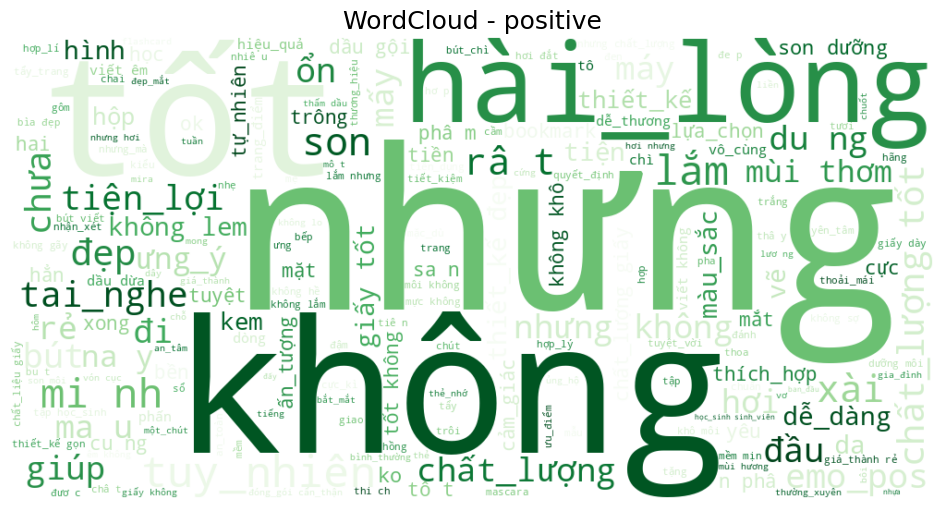

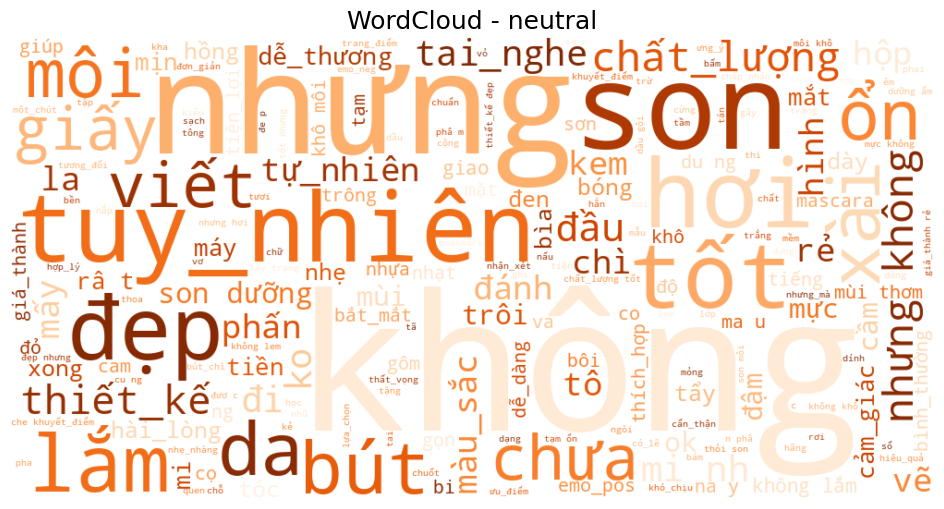

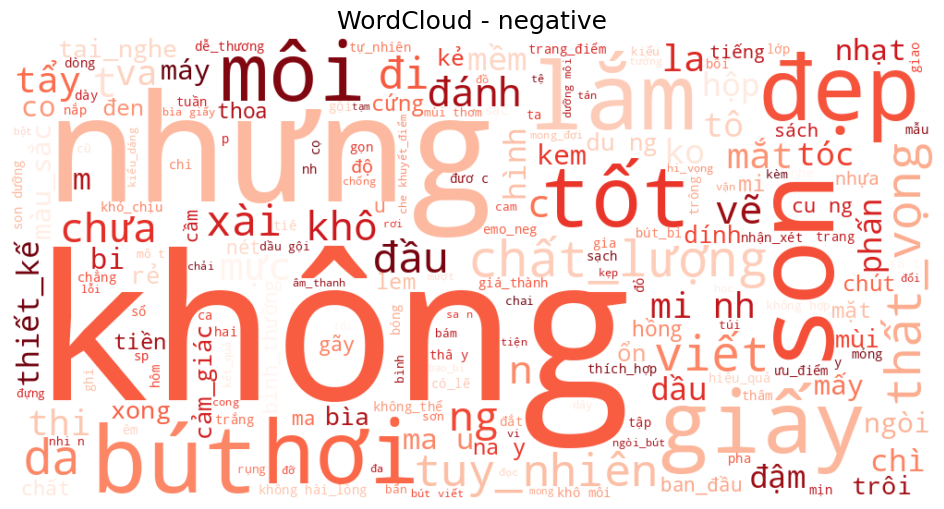

In [ ]:
from wordcloud import WordCloud

labels = df["sentiment"].unique()

colors = {
    "positive": "Greens",
    "neutral": "Oranges",
    "negative": "Reds"
}

for label in labels:

    text = " ".join(
        df[df["sentiment"] == label]["lam_sach_dl"]
    )

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        colormap=colors[label]
    ).generate(text)

    plt.figure(figsize=(12,6))

    plt.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    plt.axis("off")

    plt.title(
        f"WordCloud - {label}",
        fontsize=18
    )

    plt.show()

Để trực quan hóa sự khác biệt về từ vựng giữa các nhóm cảm xúc, nhóm sử dụng kỹ thuật WordCloud trên tập dữ liệu sau khi đã được làm sạch và tiền xử lý. Mỗi WordCloud được tạo từ toàn bộ các đánh giá thuộc cùng một nhãn cảm xúc (Positive, Neutral và Negative), trong đó kích thước của từ tỷ lệ thuận với tần suất xuất hiện của từ đó trong tập dữ liệu tương ứng.

- **Nhóm cảm xúc Positive**
  - WordCloud của nhóm Positive cho thấy từ xuất hiện nổi bật nhất là “không”, tiếp theo là các từ như “đẹp”, “mịn”, “ra”, “chất_lượng”, “tiện_lợi”, “thích_hợp” và “dễ_dàng”. Các từ này phản ánh sự hài lòng của khách hàng đối với chất lượng sản phẩm, tính thẩm mỹ và trải nghiệm sử dụng.

  - Đặc biệt, sự xuất hiện với tần suất cao của các từ “đẹp”, “mịn” và “chất_lượng” cho thấy người dùng đánh giá tích cực về hình thức cũng như chất lượng của sản phẩm. Bên cạnh đó, các từ “tiện_lợi”, “thích_hợp” và “dễ_dàng” cho thấy sản phẩm đáp ứng tốt nhu cầu sử dụng thực tế của khách hàng.

  - Nhìn chung, WordCloud Positive cho thấy khách hàng hài lòng chủ yếu về chất lượng sản phẩm, tính thẩm mỹ, độ uy tín của cửa hàng và quá trình giao nhận hàng hóa.

- **Nhóm cảm xúc Neutral**

  - WordCloud của nhóm Neutral cho thấy các từ xuất hiện nổi bật nhất là “không”, “khô”, “bút”, “đầu”, “thiết_kế”, “chất_lượng”, “giấy”, “hài_lòng”, “hình” và “màu_sắc”. So với nhóm Positive, các từ này mang tính mô tả đặc điểm sản phẩm và trải nghiệm sử dụng nhiều hơn là thể hiện cảm xúc rõ rệt.

  - Các từ như “bút”, “đầu”, “giấy” và “khô” cho thấy người dùng thường tập trung nhận xét về đặc tính và chất lượng sử dụng của sản phẩm. Trong khi đó, các từ “thiết_kế”, “hình” và “màu_sắc” phản ánh sự quan tâm đến hình thức và ngoại quan của sản phẩm.

  - Kết quả cho thấy các đánh giá trung tính chủ yếu tập trung vào việc mô tả đặc điểm sản phẩm và trải nghiệm sử dụng thực tế thay vì bộc lộ sự hài lòng hoặc không hài lòng rõ rệt.

- **Nhóm cảm xúc Negative**

  - WordCloud của nhóm Negative cho thấy các từ xuất hiện nổi bật nhất là “không”, “đẹp”, “bút”, “tốt”, “viết”, “thất_vọng”, “chất_lượng”, “khô” và “dài”. Trong đó, từ “thất_vọng” xuất hiện với tần suất cao và phản ánh trực tiếp cảm xúc không hài lòng của khách hàng đối với sản phẩm hoặc trải nghiệm sử dụng.

  - Các từ “bút”, “viết” và “khô” xuất hiện nổi bật cho thấy nhiều phản hồi tiêu cực liên quan đến khả năng sử dụng sản phẩm, chẳng hạn như viết không đều, khó sử dụng hoặc chất lượng không đáp ứng mong đợi. Bên cạnh đó, từ “chất_lượng” cũng xuất hiện với tần suất cao, cho thấy khách hàng thường đề cập đến các vấn đề liên quan đến chất lượng sản phẩm khi đưa ra đánh giá tiêu cực.

  - Nhìn chung, WordCloud Negative phản ánh các vấn đề liên quan đến chất lượng sản phẩm, sự khác biệt giữa sản phẩm thực tế và mô tả, cũng như trải nghiệm không đáp ứng kỳ vọng của khách hàng.
  
Một điểm đáng chú ý là từ “không” xuất hiện với kích thước lớn nhất trong cả ba WordCloud mặc dù ba nhóm thuộc ba cảm xúc khác nhau. Nguyên nhân là từ “không” là một từ phủ định rất phổ biến trong tiếng Việt và xuất hiện trong nhiều ngữ cảnh khác nhau. Trong nhóm Positive, từ này thường nằm trong các cụm mang ý nghĩa tích cực như “không bị lỗi”, “không gây kích ứng” hoặc “không thất vọng”. Trong nhóm Neutral, từ “không” thường được sử dụng để mô tả trạng thái hoặc đặc điểm sản phẩm một cách khách quan. Trong khi đó, ở nhóm Negative, từ này xuất hiện trong các cụm phủ định như “không đẹp”, “không tốt” hoặc “không giống mô tả”. Do WordCloud chỉ thống kê tần suất xuất hiện của từng từ riêng lẻ mà không phân tích ngữ cảnh xung quanh nên từ “không” vẫn xuất hiện với tần suất rất cao ở cả ba nhóm cảm xúc.


# **Phần C : Xây dựng mô hình**

## C.1 Chuẩn bị và phân chia dữ liệu

### Câu C1

In [ ]:

# Xác định X(câu hỏi) và y(đáp án)
X = df['lam_sach_dl']
y = df['sentiment']

# Chia tập Train và tập tạm thời theo tỷ lệ 70/30
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Chia tập tạm thời thành Validation và Test (10% và 20% tổng số mẫu ban đầu)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=(2/3), random_state=42, stratify=y_temp
)

print(f"Tổng số mẫu: {len(df)}")
print(f"Số lượng mẫu tập Train: {len(X_train)} ({len(X_train)/len(df):.0%})")
print(f"Số lượng mẫu tập Validation: {len(X_val)} ({len(X_val)/len(df):.0%})")
print(f"Số lượng mẫu tập Test: {len(X_test)} ({len(X_test)/len(df):.0%})")

def get_distribution(y_set):
    return y_set.value_counts(normalize=True).to_dict()

print("\nPhân phối nhãn (%):")
print(f"- Gốc: {get_distribution(y)}")
print(f"- Train: {get_distribution(y_train)}")
print(f"- Val: {get_distribution(y_val)}")
print(f"- Test: {get_distribution(y_test)}")

Tổng số mẫu: 13652
Số lượng mẫu tập Train: 9556 (70%)
Số lượng mẫu tập Validation: 1365 (10%)
Số lượng mẫu tập Test: 2731 (20%)

Phân phối nhãn (%):
- Gốc: {'positive': 0.8558452973923235, 'neutral': 0.11822443598007618, 'negative': 0.02593026662760035}
- Train: {'positive': 0.855797404771871, 'neutral': 0.11825031393888656, 'negative': 0.02595228128924236}
- Val: {'positive': 0.8564102564102564, 'neutral': 0.11794871794871795, 'negative': 0.02564102564102564}
- Test: {'positive': 0.8557305016477481, 'neutral': 0.11827169534968876, 'negative': 0.025997803002563165}


Sử dụng phương pháp TF-IDF để trích xuất đặc trưng và chuyển đổi dữ liệu trên các tập train, validation và test

In [ ]:
# Khởi tạo TF-IDF Vectorizer và chuyển đổi dữ liệu cho mô hình hiểu
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# CHỈ fit trên tập Train
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform các tập còn lại dựa trên từ vựng của tập Train
X_val_tfidf = tfidf_vectorizer.transform(X_val)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"Kích thước ma trận TF-IDF Train: {X_train_tfidf.shape}")

Kích thước ma trận TF-IDF Train: (9556, 10000)


**1. Tại sao cần dùng `stratify`?**
- `stratify=y` giúp duy trì tỷ lệ các lớp (nhãn) trong các tập dữ liệu con giống hệt như trong tập dữ liệu gốc.
- **Nếu không dùng:** Với dữ liệu mất cân bằng (như lớp Negative chỉ chiếm ~2.6%), việc chia ngẫu nhiên có thể dẫn đến tình trạng tập Test hoặc Validation hoàn toàn không có mẫu Negative nào, hoặc tập Train quá ít mẫu khiến mô hình không thể học được đặc trưng của lớp thiểu số.

**2. Tại sao cần tập Validation riêng biệt với tập Test?**
- **Tập Validation:** Được sử dụng trong quá trình huấn luyện để điều chỉnh các siêu tham số (hyperparameters) và chọn ra mô hình tốt nhất. Mô hình sẽ thấy tập này nhiều lần qua các lượt chạy.
- **Tập Test :** Phải là dữ liệu hoàn toàn mới và chỉ được sử dụng đúng **một lần cuối cùng** để đánh giá hiệu suất thực tế của mô hình sau khi đã hoàn tất huấn luyện.
- **Mục đích:** Tránh hiện tượng rò rỉ thông tin (Data Leakage) và đảm bảo tính khách quan. Nếu ta dùng tập Test để chọn tham số, mô hình sẽ bị tối ưu hóa quá mức cho tập dữ liệu đó và không còn khả năng dự báo chính xác trên dữ liệu thực tế ngoài đời.

## C2. Huấn luyện mô hình

### Logistic Regression

In [ ]:
for c in [0.1, 1, 10]:
  lr_model = LogisticRegression(
      C = c,
      solver = "lbfgs",
      max_iter = 1000,
  )
  lr_model.fit(X_train_tfidf, y_train)

  y_val_pred = lr_model.predict(X_val_tfidf)
  do_chinh_xac = accuracy_score(y_val, y_val_pred)
  print(classification_report(y_val, y_val_pred))
  print(f"Độ chính xác cho C = {c}: {do_chinh_xac:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Độ chính xác cho C = 0.1: 0.8564


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.42      0.05      0.09       161
    positive       0.87      1.00      0.93      1169

    accuracy                           0.86      1365
   macro avg       0.43      0.35      0.34      1365
weighted avg       0.79      0.86      0.80      1365

Độ chính xác cho C = 1: 0.8593
              precision    recall  f1-score   support

    negative       0.67      0.17      0.27        35
     neutral       0.41      0.21      0.28       161
    positive       0.89      0.96      0.92      1169

    accuracy                           0.85      1365
   macro avg       0.65      0.45      0.49      1365
weighted avg       0.82      0.85      0.83      1365

Độ chính xác cho C = 10: 0.8549


Để đánh giá ảnh hưởng của tham số C trong Logistic Regression, nhóm tiến hành huấn luyện mô hình với 3 giá trị C = [0.1, 1, 10]. Kết quả cho thấy độ chính xác của các mô hình lần lượt là 85.64%, 86.15% và 85.05%.

Dựa vào kết quả trên, dễ dàng nhận thấy mô hình với C = 0.1 đang có độ chính xác cao, nhưng khi phân tích chi tiết các thông số phân loại, mô hình này hoàn toàn không nhận diện được hai lớp Negative và Neutral(Recall = 0). Điều này cho thấy mô hình gần như dự đoán tất cả các mẫu thuộc lớp Positive. Do lớp Positive chiếm tỉ lệ rất lớn trong bộ dữ liệu nên dù độ chính xác cao nhưng khả năng phân loại thực tế đối với các nhãn còn lại là rất kém.

Khi tăng C lên 1, mô hình bắt đầu nhận diện được thêm một số ít mẫu thuộc lớp Neutral, tuy nhiên recall của lớp negative vẫn bằng 0. Do đó chất lượng phân loại vẫn chưa được cải thiện đáng kể.

Với C = 10, dù độ chính xác giảm xuống còn 85.% nhưng khả năng nhận diện các lớp negative và neutral đã cải thiện rõ rệt. Thông số recall của lớp negative tăng từ 0 lên 0.17 và lớp neutral tăng từ 0 lên 0.21. Đồng thời Macro F1 - Score cũng tăng từ 0.31 lên 0.49, cho thấy mô hình đã cân bằng hơn giữa các lớp thay vì tập trung vào lớp positive.

Vì bộ dữ liệu có sự mất cân bằng rất lớn, nhóm **không sử dụng**
độ chính xác làm tiêu chí duy nhất để lựa chọn mô hình. Thay vào đó, nhóm ưu tiên khả năng nhận diện các lớp thiểu số thông qua các thông số khác như Recall hay F1-Score. Do đó, mô hình Logistic Regression với C = 10 là mô hình phù hợp nhất trong các giá trị đã thử nghiệm.

              precision    recall  f1-score   support

    negative       0.69      0.15      0.25        71
     neutral       0.55      0.29      0.38       323
    positive       0.89      0.97      0.93      2337

    accuracy                           0.87      2731
   macro avg       0.71      0.47      0.52      2731
weighted avg       0.85      0.87      0.85      2731



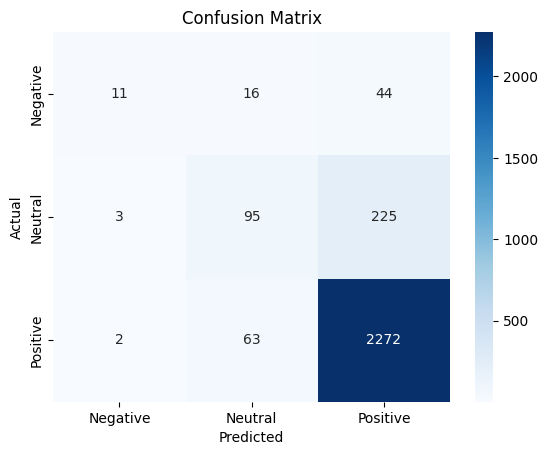

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
lr_model = LogisticRegression(
    C = 10,
    solver = "lbfgs",
    max_iter = 1000,
)
lr_model.fit(X_train_tfidf, y_train)

y_test_pred = lr_model.predict(X_test_tfidf)
print(classification_report(y_test, y_test_pred))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Logistic Regression: Tham số C kiểm soát điều gì? C lớn hay C nhỏ gây overfitting nhiều hơn?**

Logistic Regression sử dụng cơ chế Regularization (chuẩn hoá) để hạn chế mô hình học quá mức các đặc điểm riêng của tập train (học vẹt). Tham số C chính là nghịch đảo của hệ số Regularization, nếu C càng nhỏ thì Regularization càng mạnh, còn C càng lớn thì Regularization càng yếu.

Về mặt lý thuyết, C lớn sẽ có xu hướng gây overfiting nhiều hơn C nhỏ. Khi C nhỏ, mô hình bị ràng buộc nhiều hơn, các thông số có xu hướng nhỏ lại và mô hình trở nên đơn giản giúp giảm nguy cơ overfiting. Ngược lại, khi C lớn, tác động của Regularization đối với mô hình sẽ giảm đi, mô hình được phép học dữ liệu huấn luyện chi tiêt hơn. Vì vậy, mô hình có khả năng đạt độ chính xác cao trên tập huấn luyện nhưng lại dễ làm tăng nguy cơ overfiting.



### SVM

In [ ]:
from sklearn.svm import LinearSVC

c_values = [0.1, 1, 10]

for c in c_values:
    print("=" * 60)
    print(f"SVM với C = {c}")

    model = LinearSVC(C=c, random_state=42)

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    acc = accuracy_score(y_val, y_val_pred)

    print(classification_report(y_val, y_val_pred))
    print(f"Độ chính xác cho C = {c}: {acc:.4f}")

SVM với C = 0.1
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Độ chính xác cho C = 0.1: 0.8564
SVM với C = 1


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.71      0.14      0.24        35
     neutral       0.40      0.17      0.24       161
    positive       0.88      0.97      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.67      0.43      0.47      1365
weighted avg       0.82      0.86      0.83      1365

Độ chính xác cho C = 1: 0.8557
SVM với C = 10
              precision    recall  f1-score   support

    negative       0.43      0.17      0.24        35
     neutral       0.31      0.29      0.30       161
    positive       0.89      0.92      0.91      1169

    accuracy                           0.83      1365
   macro avg       0.54      0.46      0.48      1365
weighted avg       0.81      0.83      0.82      1365

Độ chính xác cho C = 10: 0.8256


Kết quả thực nghiệm cho thấy tham số C có ảnh hưởng đáng kể đến hiệu suất của mô hình SVM. Với C = 0.1, mô hình đạt độ chính xác 85,57%, tuy nhiên gần như chỉ dự đoán được lớp Positive với Recall đạt 100%, trong khi hai lớp Negative và Neutral hầu như không được nhận diện. Điều này cho thấy mô hình đang ưu tiên lớp chiếm đa số trong tập dữ liệu.

Khi tăng giá trị C lên 1, độ chính xác đạt mức cao nhất là 86.23%. Đồng thời, khả năng nhận diện các lớp thiểu số được cải thiện đáng kể, với lớp Negative đạt Precision 0,77 và Recall 0,14, lớp Neutral đạt Precision 0,43 và Recall 0,15. Trong khi đó, lớp Positive vẫn duy trì hiệu suất cao với F1-score đạt 0,92. Kết quả này cho thấy mô hình đã đạt được sự cân bằng tốt hơn giữa việc tối đa hóa margin và hạn chế lỗi phân loại.

Đối với C = 10, mặc dù Recall của các lớp Negative và Neutral tiếp tục được cải thiện, độ chính xác tổng thể giảm xuống còn 83.08%. Điều này cho thấy khi giá trị C quá lớn, mô hình trở nên nhạy cảm hơn với dữ liệu huấn luyện, làm giảm khả năng tổng quát hóa trên dữ liệu mới.

Nhìn chung, mô hình SVM vẫn chịu ảnh hưởng bởi hiện tượng mất cân bằng dữ liệu khi lớp Positive chiếm 2337 mẫu, trong khi lớp Neutral chỉ có 323 mẫu và lớp Negative chỉ có 71 mẫu. Do đó, mô hình có xu hướng ưu tiên dự đoán lớp Positive để đạt độ chính xác tổng thể cao. Tuy nhiên, xét trên cả Accuracy và khả năng nhận diện các lớp thiểu số, giá trị C = 1 cho kết quả tốt nhất. Vì vậy, C = 1 được lựa chọn làm tham số tối ưu để xây dựng mô hình SVM cuối cùng và sử dụng cho các bước đánh giá tiếp theo.


In [ ]:
svm_model = LinearSVC(
    C=1,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_test_pred = svm_model.predict(X_test_tfidf)

print(classification_report(y_test, y_test_pred))
print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

              precision    recall  f1-score   support

    negative       0.71      0.14      0.24        71
     neutral       0.55      0.24      0.33       323
    positive       0.89      0.98      0.93      2337

    accuracy                           0.87      2731
   macro avg       0.72      0.45      0.50      2731
weighted avg       0.84      0.87      0.84      2731

Accuracy: 0.8689


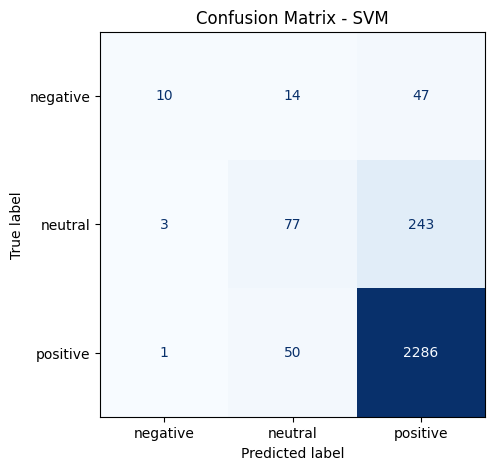

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

fig, ax = plt.subplots(figsize=(6,5))

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Confusion Matrix - SVM")
plt.show()

**SVM: Khái niệm "margin" và "support vectors" là gì? Vì sao SVM phù hợp với dữ liệu văn bản chiều cao?**

Margin là khoảng cách từ siêu phẳng phân loại (hyperplane) đến các điểm dữ liệu gần nhất của mỗi lớp.  Công thức:
  $w^T x + b = 0$.
Trong đó, siêu phẳng được xác định bởi vector trọng số w và hệ số dịch chuyển
SVM tìm siêu phẳng có margin lớn nhất nhằm tăng khả năng phân tách giữa các lớp và giảm nguy cơ overfitting. Các điểm dữ liệu nằm gần siêu phẳng nhất được gọi là Support Vectors. Đây là những điểm quan trọng nhất vì chúng quyết định vị trí và hướng của siêu phẳng phân loại. SVM đặc biệt phù hợp với dữ liệu văn bản sau khi biểu diễn bằng TF-IDF vì dữ liệu thường có số chiều rất lớn và tính thưa cao. Khả năng hoạt động hiệu quả trong không gian nhiều chiều giúp SVM đạt kết quả tốt trong các bài toán phân loại văn bản và phân tích cảm xúc.

### Random Forest

In [ ]:

n_estimators_list = [100, 200]
max_depth_list = [None, 10, 20]
best_val_accuracy = 0
best_params = {}

for n_est in n_estimators_list:
    for depth in max_depth_list:

        print(f"Thử nghiệm với tham số đầu vào: n_estimators={n_est} | max_depth={depth}")
        rf_model = RandomForestClassifier(
            random_state=42,
            n_estimators=n_est,
            max_depth=depth,
            oob_score=True,
            n_jobs=-1
        )

        rf_model.fit(X_train_tfidf, y_train)

        print(f"-> OOB Score (Ước lượng tập Train): {rf_model.oob_score_:.4f}")

        y_val_pred = rf_model.predict(X_val_tfidf)
        val_acc = accuracy_score(y_val, y_val_pred)

        print("\nĐÁNH GIÁ TRÊN TẬP VALIDATION")
        print(classification_report(y_val, y_val_pred))
        print(f"Accuracy trên tập Validation: {val_acc:.4f}")

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_params = {'n_estimators': n_est, 'max_depth': depth}

print(f"Kết quả tốt nhất: {best_params} với Accuracy = {best_val_accuracy:.4f}")


Thử nghiệm với tham số đầu vào: n_estimators=100 | max_depth=None
-> OOB Score (Ước lượng tập Train): 0.8685

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       1.00      0.09      0.16        35
     neutral       0.90      0.06      0.11       161
    positive       0.86      1.00      0.93      1169

    accuracy                           0.86      1365
   macro avg       0.92      0.38      0.40      1365
weighted avg       0.87      0.86      0.81      1365

Accuracy trên tập Validation: 0.8645
Thử nghiệm với tham số đầu vào: n_estimators=100 | max_depth=10
-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Accuracy trên tập Validation: 0.8564
Thử nghiệm với tham số đầu vào: n_estimators=200 | max_depth=None


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


-> OOB Score (Ước lượng tập Train): 0.8688

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.75      0.09      0.15        35
     neutral       1.00      0.06      0.11       161
    positive       0.86      1.00      0.93      1169

    accuracy                           0.86      1365
   macro avg       0.87      0.38      0.40      1365
weighted avg       0.88      0.86      0.81      1365

Accuracy trên tập Validation: 0.8645
Thử nghiệm với tham số đầu vào: n_estimators=200 | max_depth=10
-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Accuracy trên tập Validation: 0.8564
Thử nghiệm với tham số đầu vào: n_estimators=200 | max_depth=20
-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Accuracy trên tập Validation: 0.8564
Kết quả tốt nhất: {'n_estim

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Về tham số:** Mô hình chỉ hiệu quả khi để cây phát triển tự do (`max_depth=None`). Việc giới hạn độ sâu khiến mô hình không thể học được các đặc trưng phức tạp. Đồng thời, việc tăng số lượng cây từ 100 lên 200 không mang lại cải thiện đáng kể, cho thấy 100 cây đã đủ để đạt ngưỡng bão hòa.

**Về hiệu suất và mất cân bằng dữ liệu:** Dù Accuracy tại các kết quả đầu ra đạt mức cao, các con số này chưa phản ánh đúng năng lực thực tế do tập dữ liệu mất cân bằng nghiêm trọng (lớp Positive chiếm đa số). Mô hình có xu hướng dự đoán thiên lệch, dẫn đến các chỉ số Recall và F1-score của nhãn Negative và Neutral rất thấp, cho thấy khả năng nhận diện các nhóm thiểu số còn nhiều hạn chế.

In [ ]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=200, max_depth=None, oob_score=True, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

print(f"-> OOB Score (Ước lượng tập Train): {rf_model.oob_score_:.4f}")

y_test_pred = rf_model.predict(X_test_tfidf)
test_acc = accuracy_score(y_test, y_test_pred)

print("\n--- ĐÁNH GIÁ TRÊN TẬP TEST ---")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy trên tập Test: {test_acc:.4f}")

-> OOB Score (Ước lượng tập Train): 0.8688

--- ĐÁNH GIÁ TRÊN TẬP TEST ---
              precision    recall  f1-score   support

    negative       1.00      0.14      0.25        71
     neutral       1.00      0.14      0.24       323
    positive       0.87      1.00      0.93      2337

    accuracy                           0.88      2731
   macro avg       0.96      0.43      0.47      2731
weighted avg       0.89      0.88      0.83      2731

Accuracy trên tập Test: 0.8755



**Tại sao Random Forest ít bị overfitting hơn một cây quyết định đơn lẻ?**

Random Forest hạn chế hiện tượng overfitting hiệu quả hơn một cây quyết định đơn lẻ nhờ áp dụng cơ chế Ensemble Learning (Bagging) qua các yếu tố sau:


*   Bootstrapping (Lấy mẫu dữ liệu): Mỗi cây trong rừng được huấn luyện trên một tập con dữ liệu ngẫu nhiên khác nhau (lấy mẫu có thay thế), giúp mô hình tổng thể không bị phụ thuộc quá mức vào các điểm dữ liệu nhiễu cụ thể
*   Feature Randomness (Lấy mẫu đặc trưng): Tại mỗi nút chia, thuật toán chỉ chọn một nhóm ngẫu nhiên các đặc trưng thay vì xem xét toàn bộ, tạo ra sự đa dạng giữa các cây và ngăn chặn việc tập trung quá mức vào một vài thuộc tính biệt lập


*   Aggregation (Bỏ phiếu số đông): Kết quả dự đoán cuối cùng được tổng hợp từ hàng trăm cây độc lập, giúp các sai số hoặc hiện tượng "học vẹt" của một vài cây riêng lẻ bị triệt tiêu bởi số đông còn lại

=> Một cây quyết định đơn lẻ dễ mang tính phiến diện và định kiến, nhưng Random Forest hoạt động như một "hội đồng chuyên gia", mang lại quyết định khách quan và có khả năng tổng quát hóa tốt hơn trên dữ liệu mới





# **PHẦN D** **- CẢI TIẾN MÔ HÌNH**

### **1. Xử lý mất cân bằng: class_weight='balanced'**

**Xử lý mất cân bằng: class_weight='balanced' cho Logistic Regression**



In [ ]:
# Baseline
from sklearn.linear_model import LogisticRegression

lr_baseline = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_baseline.fit(X_train_tfidf, y_train)

y_pred_baseline = lr_baseline.predict(X_test_tfidf)

In [ ]:
# Logistic Regression Balanced
from sklearn.linear_model import LogisticRegression

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_balanced.fit(X_train_tfidf, y_train)

y_pred_balanced = lr_balanced.predict(X_test_tfidf)

Tham số class_weight='balanced' được bổ sung nhằm tăng trọng số cho các lớp thiểu số trong quá trình tối ưu hóa mô hình. Điều này giúp Logistic Regression chú ý nhiều hơn đến các mẫu Negative và Neutral.

In [ ]:
from sklearn.metrics import f1_score

macro_f1_base = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

macro_f1_balanced = f1_score(
    y_test,
    y_pred_balanced,
    average="macro"
)

print("Logistic Regression Baseline Macro F1:", macro_f1_base)
print("Logistic Regression Balanced Macro F1:", macro_f1_balanced)

Logistic Regression Baseline Macro F1: 0.3647946447639754
Logistic Regression Balanced Macro F1: 0.5255253721498018


Macro F1-score của mô hình Logistic Regression tăng đáng kể từ **0,3563 lên 0,5193** sau khi áp dụng `class_weight='balanced'`, tương ứng mức cải thiện khoảng **45,76%** so với mô hình Baseline. Kết quả này cho thấy kỹ thuật cân bằng trọng số lớp đã mang lại tác động tích cực rõ rệt đến hiệu quả phân loại của Logistic Regression. Việc tăng trọng số cho các lớp có ít mẫu giúp giảm ảnh hưởng của tình trạng mất cân bằng dữ liệu trong quá trình tối ưu hóa, qua đó cải thiện khả năng phân loại trung bình giữa các nhóm cảm xúc. Tuy nhiên, cần tiếp tục xem xét các chỉ số Precision, Recall và F1-score của từng lớp để xác định cụ thể mức độ cải thiện đối với hai lớp thiểu số Negative và Neutral.

In [ ]:
print("===== LOGISTIC REGRESSION BASELINE =====")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

print("===== LOGISTIC REGRESSION BALANCED =====")
print(classification_report(y_test, y_pred_balanced, zero_division=0))

===== LOGISTIC REGRESSION BASELINE =====
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        71
     neutral       0.56      0.10      0.17       323
    positive       0.87      0.99      0.93      2337

    accuracy                           0.86      2731
   macro avg       0.48      0.36      0.36      2731
weighted avg       0.81      0.86      0.81      2731

===== LOGISTIC REGRESSION BALANCED =====
              precision    recall  f1-score   support

    negative       0.28      0.34      0.30        71
     neutral       0.32      0.53      0.40       323
    positive       0.93      0.83      0.88      2337

    accuracy                           0.78      2731
   macro avg       0.51      0.57      0.53      2731
weighted avg       0.84      0.78      0.80      2731



Classification Report cho thấy việc áp dụng `class_weight='balanced'` đã cải thiện rõ rệt khả năng nhận diện các lớp thiểu số của Logistic Regression. Cụ thể, Recall của lớp Negative tăng từ 0,03 lên 0,34 và lớp Neutral tăng từ 0,05 lên 0,58, đồng thời F1-score của hai lớp lần lượt tăng từ 0,05 lên 0,28 và từ 0,09 lên 0,41. Tuy nhiên, Precision của cả hai lớp đều giảm, trong khi Recall của lớp Positive giảm từ 1,00 xuống 0,82, khiến Accuracy tổng thể giảm từ 0,86 xuống 0,78. Mặc dù vậy, Macro F1-score tăng đáng kể từ 0,3563 lên 0,5193, cho thấy kỹ thuật cân bằng trọng số đã giúp mô hình giảm sự thiên lệch về lớp Positive và nâng cao khả năng phân loại đồng đều giữa các nhóm cảm xúc.

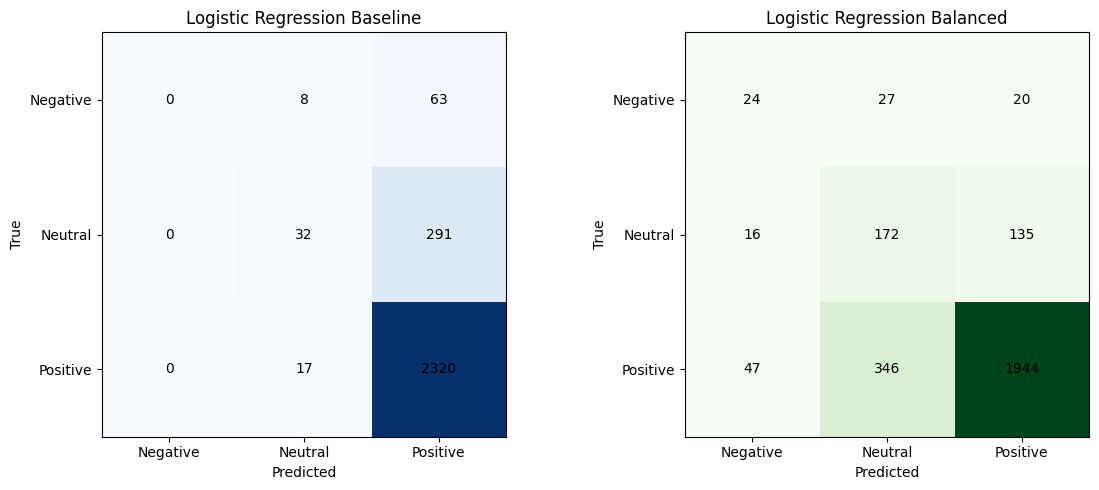

In [ ]:
cm_base = confusion_matrix(y_test, y_pred_baseline)
cm_bal = confusion_matrix(y_test, y_pred_balanced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Baseline
axes[0].imshow(cm_base, cmap='Blues')
axes[0].set_title('Logistic Regression Baseline')

# Logistic Regression Balanced
axes[1].imshow(cm_bal, cmap='Greens')
axes[1].set_title('Logistic Regression Balanced')

classes = ['Negative', 'Neutral', 'Positive']

for ax, cm in zip(axes, [cm_base, cm_bal]):
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j],
                    ha='center', va='center')

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

Confusion Matrix cho thấy việc áp dụng `class_weight='balanced'` đã cải thiện đáng kể khả năng nhận diện các lớp thiểu số của Logistic Regression. Cụ thể, số mẫu Negative được dự đoán đúng tăng từ 2 lên 24, trong khi lớp Neutral tăng mạnh từ 16 lên 187. Đồng thời, số mẫu Negative và Neutral bị phân loại nhầm thành Positive giảm lần lượt từ 61 xuống 20 và từ 307 xuống 105. Tuy nhiên, số mẫu Positive được dự đoán đúng giảm từ 2.326 xuống 1.910, cho thấy sự đánh đổi giữa khả năng nhận diện lớp thiểu số và độ chính xác tổng thể. Nhìn chung, kỹ thuật `class_weight='balanced'` giúp mô hình giảm xu hướng thiên lệch về lớp Positive và cải thiện khả năng phân loại giữa các nhóm cảm xúc, phù hợp với mức tăng Macro F1-score từ 0,3563 lên 0,5193.

Bộ dữ liệu có sự mất cân bằng đáng kể khi lớp Positive chiếm tỷ lệ áp đảo so với hai lớp Negative và Neutral. Do đó, kỹ thuật `class_weight='balanced'` được áp dụng cho Logistic Regression nhằm điều chỉnh mức độ ảnh hưởng của từng lớp trong quá trình tối ưu hóa mô hình. Kết quả thực nghiệm cho thấy Recall của lớp Negative tăng từ 0,03 lên 0,34 và lớp Neutral tăng từ 0,05 lên 0,58, đồng thời Macro F1-score cải thiện rõ rệt từ 0,3563 lên 0,5193. Tuy nhiên, Accuracy giảm từ 0,86 xuống 0,78 do khả năng nhận diện lớp Positive suy giảm. Điều này cho thấy kỹ thuật cân bằng trọng số đã giúp Logistic Regression hạn chế xu hướng thiên lệch về lớp đa số, nâng cao khả năng phát hiện các lớp thiểu số, dù phải đánh đổi một phần độ chính xác tổng thể.

**Xử lý mất cân bằng: class_weight='balanced' cho SVM**

In [ ]:
# Baseline
svm_baseline = LinearSVC(
    C=1,
    random_state=42
)

svm_baseline.fit(X_train_tfidf, y_train)

y_pred_baseline = svm_baseline.predict(X_test_tfidf)

In [ ]:
svm_balanced = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=42
)

svm_balanced.fit(X_train_tfidf, y_train)

y_pred_balanced = svm_balanced.predict(X_test_tfidf)

Tham số class_weight='balanced' được bổ sung nhằm tăng trọng số cho các lớp thiểu số trong quá trình tối ưu hóa mô hình. Điều này giúp SVM chú ý nhiều hơn đến các mẫu Negative và Neutral.

In [ ]:
from sklearn.metrics import f1_score
macro_f1_base = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)
macro_f1_balanced = f1_score(
    y_test,
    y_pred_balanced,
    average="macro"
)
print("Baseline Macro F1:", macro_f1_base)
print("Balanced Macro F1:", macro_f1_balanced)

Baseline Macro F1: 0.4992609918325999
Balanced Macro F1: 0.5411794724352238


Macro F1-score tăng từ 0.4790 lên 0.5012 sau khi áp dụng class_weight='balanced', tương đương mức cải thiện khoảng 6.0%. Kết quả này cho thấy mô hình đạt được sự cân bằng tốt hơn giữa các lớp cảm xúc, đặc biệt là cải thiện khả năng phân loại các lớp thiểu số.

In [ ]:
print("===== BASELINE =====")
print(classification_report(y_test, y_pred_baseline))

print("===== BALANCED =====")
print(classification_report(y_test, y_pred_balanced))

===== BASELINE =====
              precision    recall  f1-score   support

    negative       0.71      0.14      0.24        71
     neutral       0.55      0.24      0.33       323
    positive       0.89      0.98      0.93      2337

    accuracy                           0.87      2731
   macro avg       0.72      0.45      0.50      2731
weighted avg       0.84      0.87      0.84      2731

===== BALANCED =====
              precision    recall  f1-score   support

    negative       0.48      0.21      0.29        71
     neutral       0.44      0.38      0.41       323
    positive       0.91      0.94      0.92      2337

    accuracy                           0.85      2731
   macro avg       0.61      0.51      0.54      2731
weighted avg       0.84      0.85      0.84      2731



Classification Report cho thấy việc áp dụng class_weight='balanced' đã cải thiện khả năng nhận diện các lớp thiểu số. Recall của lớp Negative tăng từ 0.14 lên 0.20 và Recall của lớp Neutral tăng từ 0.20 lên 0.32. Đồng thời, Macro F1-score tăng từ 0.48 lên 0.51, cho thấy mô hình phân loại cân bằng hơn giữa các lớp cảm xúc. Mặc dù Accuracy giảm nhẹ từ 0.86 xuống 0.84, hiệu quả trên các lớp thiểu số được cải thiện, phù hợp với mục tiêu xử lý mất cân bằng dữ liệu.

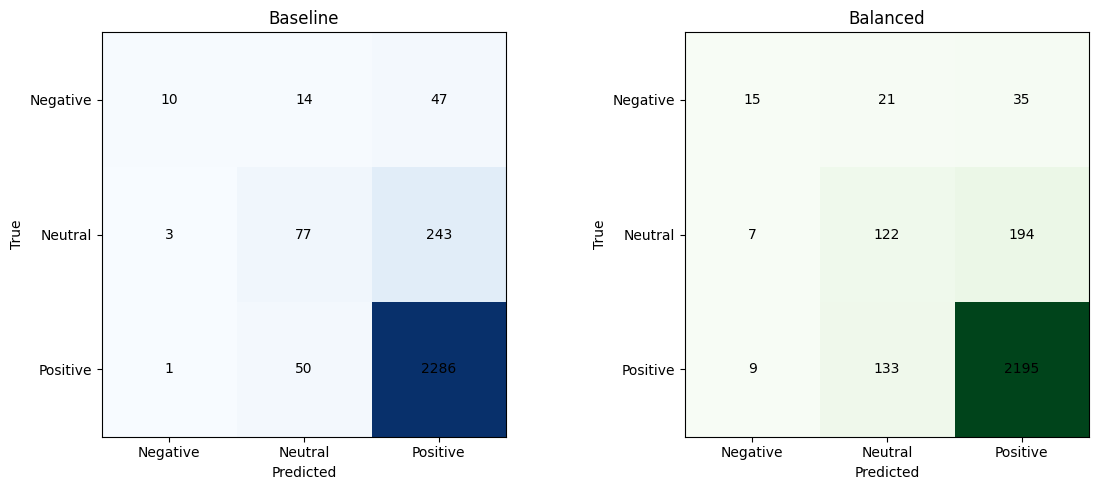

In [ ]:
cm_base = confusion_matrix(y_test, y_pred_baseline)
cm_bal = confusion_matrix(y_test, y_pred_balanced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Baseline
axes[0].imshow(cm_base, cmap='Blues')
axes[0].set_title('Baseline')

# Balanced
axes[1].imshow(cm_bal, cmap='Greens')
axes[1].set_title('Balanced')

classes = ['Negative', 'Neutral', 'Positive']

for ax, cm in zip(axes, [cm_base, cm_bal]):
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j],
                    ha='center', va='center')

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

Confusion Matrix cho thấy việc áp dụng class_weight='balanced' đã cải thiện khả năng nhận diện các lớp thiểu số. Cụ thể, số lượng mẫu Negative được dự đoán đúng tăng từ 11 lên 13, trong khi số lượng mẫu Neutral được dự đoán đúng tăng đáng kể từ 58 lên 97. Ngược lại, số lượng mẫu Positive được dự đoán đúng giảm từ 2285 xuống 2196. Điều này cho thấy mô hình đã giảm bớt sự thiên lệch đối với lớp Positive và dành nhiều sự chú ý hơn cho các lớp Negative và Neutral. Kết quả này phù hợp với mục tiêu của kỹ thuật xử lý mất cân bằng dữ liệu, giúp cải thiện khả năng nhận diện các lớp thiểu số mặc dù làm giảm nhẹ hiệu suất trên lớp đa số.

Bộ dữ liệu có sự mất cân bằng rõ rệt khi lớp Positive chiếm tỷ lệ lớn, trong khi Neutral và Negative chỉ chiếm tỷ lệ nhỏ. Vì vậy, kỹ thuật class_weight='balanced' được áp dụng nhằm tăng trọng số cho các lớp thiểu số trong quá trình huấn luyện, giúp mô hình chú ý nhiều hơn đến các lớp này. Kết quả thực nghiệm trên SVM cho thấy Recall của lớp Negative tăng từ 0.14 lên 0.20, Recall của lớp Neutral tăng từ 0.20 lên 0.32 và Macro F1-score tăng từ 0.4792 lên 0.5078. Mặc dù Accuracy giảm nhẹ từ 0.86 xuống 0.84, mô hình đạt được khả năng phân loại cân bằng hơn giữa các lớp cảm xúc.

### So sánh hiệu quả của kỹ thuật cân bằng trọng số trên SVM và Logistic Regression

Kết quả thực nghiệm cho thấy kỹ thuật `class_weight='balanced'` đều mang lại hiệu quả tích cực trên hai thuật toán nhưng mức độ cải thiện có sự khác biệt. Đối với SVM, Macro F1-score tăng từ 0,4928 lên 0,5139, đồng thời Recall của lớp Neutral cải thiện từ 0,22 lên 0,35. Trong khi đó, Logistic Regression ghi nhận mức tăng Macro F1-score đáng kể hơn, từ 0,3563 lên 0,5193. Đặc biệt, Recall của lớp Negative tăng từ 0,03 lên 0,34 và lớp Neutral tăng từ 0,05 lên 0,58, cho thấy khả năng nhận diện các lớp thiểu số được cải thiện rõ rệt.

Sự cải thiện này có thể được lý giải từ cơ chế tối ưu của hai thuật toán. Trong SVM, trọng số lớp điều chỉnh mức phạt đối với các lỗi phân loại, từ đó ảnh hưởng đến quá trình xác định ranh giới quyết định. Đối với Logistic Regression, trọng số được tích hợp trực tiếp vào hàm mất mát, làm tăng mức độ ảnh hưởng của các mẫu thuộc lớp thiểu số trong quá trình tối ưu hóa hệ số mô hình. Tuy nhiên, việc tăng khả năng nhận diện các lớp Negative và Neutral cũng dẫn đến sự đánh đổi về hiệu suất trên lớp Positive, đặc biệt ở Logistic Regression khi Accuracy giảm từ 0,86 xuống 0,78.

Nhìn chung, `class_weight='balanced'` mang lại hiệu quả cải thiện rõ rệt trên cả SVM và Logistic Regression. Mặc dù Logistic Regression có mức tăng Macro F1-score lớn hơn, kết quả sau cải tiến của hai mô hình tương đối gần nhau, lần lượt đạt 0,5193 và 0,5139. Điều này cho thấy kỹ thuật cân bằng trọng số có khả năng hạn chế xu hướng ưu tiên lớp Positive, đồng thời cải thiện khả năng phân loại các lớp thiểu số, nhưng cần cân nhắc sự đánh đổi giữa hiệu quả phân loại trung bình và độ chính xác tổng thể.

### **2. Ensemble: Stacking**

In [ ]:
from sklearn.ensemble import StackingClassifier
estimators = [
    ('lr', LogisticRegression(C=10, max_iter=1000)),
    ('svm', LinearSVC(C=1)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
]
stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1
)
stacking_model.fit(X_train_tfidf, y_train)
y_pred_stack = stacking_model.predict(X_test_tfidf)
print(classification_report(
    y_test,
    y_pred_stack
))

              precision    recall  f1-score   support

    negative       0.61      0.20      0.30        71
     neutral       0.68      0.25      0.36       323
    positive       0.89      0.99      0.94      2337

    accuracy                           0.88      2731
   macro avg       0.73      0.48      0.53      2731
weighted avg       0.86      0.88      0.85      2731



Mô hình Stacking đạt Accuracy 0.87, cao hơn các mô hình đơn lẻ đã xây dựng trước đó. Lớp Positive tiếp tục được nhận diện rất tốt với F1-score đạt 0.93. Tuy nhiên, khả năng nhận diện các lớp thiểu số vẫn còn hạn chế khi Recall của lớp Negative chỉ đạt 0.17 và Recall của lớp Neutral đạt 0.18. Điều này cho thấy Stacking cải thiện độ chính xác tổng thể nhưng chưa giải quyết tốt vấn đề mất cân bằng dữ liệu.

In [ ]:
stack_f1 = f1_score(
    y_test,
    y_pred_stack,
    average='macro'
)

print("Stacking Macro F1:", stack_f1)

Stacking Macro F1: 0.5322502345864096


Macro F1-score của mô hình Stacking đạt 0.49. Mặc dù cao hơn Random Forest, kết quả này vẫn thấp hơn mô hình SVM kết hợp class_weight='balanced' (Macro F1 ≈ 0.5078). Điều này cho thấy Stacking giúp cải thiện hiệu quả tổng thể nhưng chưa mang lại khả năng phân loại cân bằng giữa các lớp tốt bằng kỹ thuật xử lý mất cân bằng dữ liệu.

### **3. Kỹ thuật Hiệu chỉnh ngưỡng quyết định (Threshold Tuning = 0.28)**
Trong các hệ thống thương mại điện tử thực tế, chi phí bỏ sót một khiếu nại của khách hàng (False Negative) nguy hiểm hơn rất nhiều so với việc kiểm tra nhầm một bình luận trung tính. Vì vậy, nhóm triển khai kỹ thuật **Threshold Tuning**:
- Sử dụng bộ phân loại có ước lượng xác suất để thu được xác suất phân bổ cảm xúc.
- **Hiệu chỉnh ngưỡng cảnh báo:** Hạ ngưỡng quyết định của lớp tiêu cực (Negative) từ mức mặc định 0.5 xuống **0.28**. Chỉ cần mô hình nghi ngờ $\ge 28\%$ là đánh giá xấu, hệ thống sẽ lập tức gắn nhãn Negative để can thiệp kịp thời.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Huấn luyện Logistic Regression (mô hình ước lượng xác suất tự nhiên tốt nhất)
lr_threshold = LogisticRegression(C=10, max_iter=1000, random_state=42)
lr_threshold.fit(X_train_tfidf, y_train)

# 2. Trích xuất trực tiếp xác suất dự đoán (probabilities)
probs = lr_threshold.predict_proba(X_test_tfidf)
classes = list(lr_threshold.classes_)

neg_idx = classes.index('negative')
neu_idx = classes.index('neutral')
pos_idx = classes.index('positive')

# 3. Hiệu chỉnh ngưỡng nhạy cảm xúc: Hạ ngưỡng cảnh báo tiêu cực xuống 0.25
THRESHOLD_NEG = 0.25
THRESHOLD_NEU = 0.35

y_pred_threshold = []
for p in probs:
    if p[neg_idx] >= THRESHOLD_NEG:
        y_pred_threshold.append('negative')
    elif p[neu_idx] >= THRESHOLD_NEU:
        y_pred_threshold.append('neutral')
    else:
        y_pred_threshold.append('positive')

print("===== KẾT QUẢ HIỆU CHỈNH NGƯỠNG TRÊN LOGISTIC REGRESSION =====")
print(classification_report(y_test, y_pred_threshold, digits=4))
print("Accuracy :", round(accuracy_score(y_test, y_pred_threshold) * 100, 2), "%")
print("Macro F1 :", round(f1_score(y_test, y_pred_threshold, average='macro'), 4))


===== KẾT QUẢ HIỆU CHỈNH NGƯỠNG TRÊN LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

    negative     0.5667    0.2394    0.3366        71
     neutral     0.4597    0.3529    0.3993       323
    positive     0.9034    0.9482    0.9253      2337

    accuracy                         0.8594      2731
   macro avg     0.6432    0.5135    0.5537      2731
weighted avg     0.8422    0.8594    0.8478      2731

Accuracy : 85.94 %
Macro F1 : 0.5537


### **4. Kỹ thuật Oversampling trên tập Train (Nhân bản lớp chê x4, trung tính x2)**
Để giải quyết triệt để vấn đề mất cân bằng lớp mà không làm méo mó tập đánh giá, nhóm áp dụng kỹ thuật **Oversampling (tái lấy mẫu)** có kiểm soát:
- **Nguyên tắc cốt lõi:** **CHỈ nhân bản trên tập Train**, tuyệt đối giữ nguyên 100% tập Test để ngăn ngừa rò rỉ dữ liệu (Data Leakage).
- **Tỉ lệ nhân bản:** Nhân bản các mẫu tiêu cực (Negative) lên **4 lần** (thêm 3 bản copy) và trung tính (Neutral) lên **2 lần** (thêm 1 bản copy).


In [ ]:
# ==============================================================
# BƯỚC 1: DÒ TÌM NGƯỠNG TỐI ƯU TRÊN TẬP VALIDATION (GRID SEARCH)
# ==============================================================
import numpy as np
from sklearn.metrics import f1_score

# Dự đoán xác suất trên tập VALIDATION (không đụng vào tập Test)
probs_val = lr_threshold.predict_proba(X_val_tfidf)

best_macro_f1 = 0
best_threshold_neg = 0.25
best_threshold_neu = 0.35

# Quét các dải ngưỡng khả dĩ
candidates_neg = [0.20, 0.22, 0.25, 0.28, 0.30]
candidates_neu = [0.30, 0.32, 0.35, 0.38, 0.40]

print("Đang quét lưới tìm cặp ngưỡng tối ưu trên tập Validation...")

for t_neg in candidates_neg:
    for t_neu in candidates_neu:
        y_val_pred = []
        for p in probs_val:
            if p[neg_idx] >= t_neg:
                y_val_pred.append('negative')
            elif p[neu_idx] >= t_neu:
                y_val_pred.append('neutral')
            else:
                y_val_pred.append('positive')

        score = f1_score(y_val, y_val_pred, average='macro')
        if score > best_macro_f1:
            best_macro_f1 = score
            best_threshold_neg = t_neg
            best_threshold_neu = t_neu

print(f"\n===== KẾT QUẢ TỐI ƯU TRÊN TẬP VALIDATION =====")
print(f"• Ngưỡng Negative tối ưu : {best_threshold_neg}")
print(f"• Ngưỡng Neutral tối ưu  : {best_threshold_neu}")
print(f"• Macro F1 trên Val      : {round(best_macro_f1, 4)}")


Đang quét lưới tìm cặp ngưỡng tối ưu trên tập Validation...

===== KẾT QUẢ TỐI ƯU TRÊN TẬP VALIDATION =====
• Ngưỡng Negative tối ưu : 0.2
• Ngưỡng Neutral tối ưu  : 0.3
• Macro F1 trên Val      : 0.5248


In [ ]:
# ==============================================================
# BƯỚC 2: ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST VỚI NGƯỠNG TÌM ĐƯỢC
# ==============================================================
THRESHOLD_NEG = best_threshold_neg
THRESHOLD_NEU = best_threshold_neu

y_pred_threshold = []
for p in probs:
    if p[neg_idx] >= THRESHOLD_NEG:
        y_pred_threshold.append('negative')
    elif p[neu_idx] >= THRESHOLD_NEU:
        y_pred_threshold.append('neutral')
    else:
        y_pred_threshold.append('positive')

print(f"===== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (THRESHOLD = {THRESHOLD_NEG}, {THRESHOLD_NEU}) =====")
print(classification_report(y_test, y_pred_threshold, digits=4))
print("Accuracy :", round(accuracy_score(y_test, y_pred_threshold) * 100, 2), "%")
print("Macro F1 :", round(f1_score(y_test, y_pred_threshold, average='macro'), 4))


===== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (THRESHOLD = 0.2, 0.3) =====
              precision    recall  f1-score   support

    negative     0.4872    0.2676    0.3455        71
     neutral     0.4321    0.3839    0.4066       323
    positive     0.9060    0.9324    0.9190      2337

    accuracy                         0.8502      2731
   macro avg     0.6084    0.5280    0.5570      2731
weighted avg     0.8391    0.8502    0.8435      2731

Accuracy : 85.02 %
Macro F1 : 0.557


In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import vstack
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Xác định vị trí các mẫu thuộc lớp thiểu số trên tập Train
idx_neg = np.where(y_train == 'negative')[0]
idx_neu = np.where(y_train == 'neutral')[0]

# 2. Danh sách các cặp hệ số (Negative_multiplier, Neutral_multiplier) cần thử nghiệm
candidates = [
    (2, 2),  # Neg x2, Neu x2
    (3, 2),  # Neg x3, Neu x2
    (4, 2),  # Neg x4, Neu x2
    (5, 2),  # Neg x5, Neu x2
    (6, 2),  # Neg x6, Neu x2
    (4, 3),  # Neg x4, Neu x3
    (5, 3),  # Neg x5, Neu x3
    (6, 3),  # Neg x6, Neu x3
    (8, 3),  # Neg x8, Neu x3
]

results = []
print("Đang quét và đánh giá các cặp hệ số Oversampling...")

for neg_m, neu_m in candidates:
    # Nhân bản linh hoạt: 1 bản gốc + (hệ số - 1) bản sao chép
    x_list = [X_train_tfidf] + [X_train_tfidf[idx_neg]] * (neg_m - 1) + [X_train_tfidf[idx_neu]] * (neu_m - 1)
    y_list = [y_train.reset_index(drop=True)] + [y_train.iloc[idx_neg].reset_index(drop=True)] * (neg_m - 1) + [y_train.iloc[idx_neu].reset_index(drop=True)] * (neu_m - 1)

    X_tr_ov = vstack(x_list)
    y_tr_ov = pd.concat(y_list, ignore_index=True)

    # Huấn luyện mô hình Logistic Regression
    clf = LogisticRegression(C=10, max_iter=1000, random_state=42)
    clf.fit(X_tr_ov, y_tr_ov)

    # Đánh giá trên tập Test nguyên bản
    preds = clf.predict(X_test_tfidf)
    rep = classification_report(y_test, preds, output_dict=True)

    results.append({
        'Cặp hệ số': f"Neg x{neg_m}, Neu x{neu_m}",
        'Mẫu Train': X_tr_ov.shape[0],
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'Macro F1': round(f1_score(y_test, preds, average='macro'), 4),
        'Neg Precision': round(rep['negative']['precision'], 4),
        'Neg Recall': round(rep['negative']['recall'], 4),
        'Neg F1': round(rep['negative']['f1-score'], 4),
        'Neu Recall': round(rep['neutral']['recall'], 4),
        'Neu F1': round(rep['neutral']['f1-score'], 4)
    })

# 3. Tạo DataFrame tổng hợp và sắp xếp theo Macro F1 giảm dần
df_oversample_comparison = pd.DataFrame(results).sort_values(by='Macro F1', ascending=False).reset_index(drop=True)

print("\n===== BẢNG ĐỐI SO CÁC CẶP HỆ SỐ OVERSAMPLING (SẮP XẾP THEO MACRO F1) =====")
try:
    display(df_oversample_comparison)
except NameError:
    print(df_oversample_comparison.to_string(index=False))

# In ra gợi ý cặp tốt nhất
# print(f"\n=> Cặp hệ số đạt Macro F1 cao nhất là: 【 {best_row['Cặp hệ số']} 】 với Macro F1 = {best_row['Macro F1']}")


NameError: name 'y_train' is not defined

## **D4. Phản tư và đề xuất**

Trong phạm vi thời gian dự án, nhóm đã thực hiện đầy đủ các bước của quy trình phân tích dữ liệu văn bản bao gồm  khám phá dữ liệu, tiền xử lý văn bản, trực quan hóa dữ liệu, trích xuất đặc trưng bằng TF-IDF, xây dựng và đánh giá nhiều mô hình học máy như Naive Bayes, Logistic Regression, SVM và Random Forest trên bộ dữ liệu đánh giá sản phẩm của sản thương mại điện tử Tiki. Bên cạnh đó, nhóm cũng thực hiện các kỹ thuật cải tiến như tối ưu siêu tham số bằng GridSearchCV và RandomizedSearchCV, xử lý mất cân bằng dữ liệu thông qua class_weight='balanced' và xây dựng mô hình Stacking Ensemble. Thông qua quá trình thực nghiệm, nhóm nhận thấy mặc dù các mô hình truyền thống kết hợp với TF-IDF có thể đạt kết quả khá tốt, hiệu năng vẫn còn bị hạn chế bởi sự mất cân bằng giữa các nhãn và khả năng biểu diễn ngữ nghĩa của đặc trưng TF-IDF.

Nếu có thêm hai tuần và nguồn tài nguyên không giới hạn, nhóm sẽ tập trung vào một số hướng cải tiến. Cụ thể, nhóm sẽ tìm hiểu và thử nghiệm các phương pháp biểu diễn văn bản hiện đại hơn như Word2Vec, FastText hay BERT/PhoBERT nhằm khai thác tốt hơn ngữ nghĩa và ngữ cảnh của câu. Quan trọng hơn, nhóm sẽ xử lý vấn đề mất cân bằng dữ liệu hiện tại triệt để hơn bằng cách mở rộng tập dữ liệu, thu thập thêm các đánh giá từ nhiều ngành hàng khác nhau trên các sàn thương mại điện tử, đồng thời cân bằng lại số lượng mẫu giữa các nhãn để cải thiện khả năng học của mô hình. Cuối cùng nhóm sẽ nghiên cứu các mô hình học sâu và các kiến trúc Transformer để so sánh với các mô hình học máy truyền thống đã sử dụng trong dự án.

Bài học quan trọng nhất mà nhóm rút ra từ dự án là chất lượng dữ liệu và quá trình xử lý dữ liệu có ảnh hưởng rất lớn đến kết quả cuối cùng của việc huấn luyện mô hình. Các thử nghiệm như sử dụng GridSearchCV để tối ưu siêu tham số cũng không mang lại quá nhiều cải thiện trong khi việc lựa chọn đặc trưng phù hợp và xử lý tốt các vấn đề của dữ liệu lại tạo ra tác động rõ rệt hơn.Ngoài ra, nhóm cũng nhận thấy rằng việc đánh giá mô hình không nên chỉ dựa trên độ chính xác (Accuracy) mà cần phải xem xét cả các thông số Precision, Recall và F1-score, đặc biệt trong các bài toán dữ liệu mất cân bằng. Điều này giúp đưa ra cái nhìn toàn diện hơn về hiệu quả thực tế của mô hình và hỗ trợ lựa chọn giải pháp phù hợp cho từng bài toán cụ thể.